# 03 - Patch Attention Visualization

Compare retrieval saliency for frozen DINOv3, Geo GRL, and patch-attention models, alongside the patch-attention model's learned attention, across matched Summer/Snow pairs.

In [37]:
import os
from pathlib import Path
import math
import sys

import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import pandas as pd
import torch
from omegaconf import OmegaConf

REPO_DIR = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
os.chdir(REPO_DIR)  # Checkpoint paths are relative to the repository root.
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from scripts.evaluate import load_trained_model
from src.datasets.seasonet import SeasoNetDataset
from src.models.backbone import load_frozen_backbone
from src.models.preprocessing import preprocess_images
from src.preprocessing.schema import Pairs
from src.utils.device import get_device

In [38]:
PATCH_ATTENTION_CHECKPOINT_PATH = REPO_DIR / (
    'artifacts/checkpoints/'
    'dinov3_vits16_patch_attention_residual_init1e-3_infonce_hard5_b256_dropout0_best.pt'
)
GEO_GRL_CHECKPOINT_PATH = REPO_DIR / (
    'artifacts/checkpoints/dinov3_vits16_geo_grl_w0.0_residual_hard_50_best.pt'
)
SPLIT = 'test'  # The PACE train/validation bundle does not include test images.
LOC_IDS = None  # Example: ['1_11.524806_49.339061', 'another_location_id']
SAMPLE_COUNT = 3  # Used only when LOC_IDS is None.
RANDOM_SEED = 42  # Change this to sample different pairs.
COLORMAP = 'magma'

for checkpoint_path in (PATCH_ATTENTION_CHECKPOINT_PATH, GEO_GRL_CHECKPOINT_PATH):
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f'Checkpoint not found: {checkpoint_path}')

In [39]:
preprocessing_cfg = OmegaConf.load(REPO_DIR / 'config/preprocessing_config.yaml')
artifacts_dir = REPO_DIR / preprocessing_cfg.output.artifacts_dir
manifest = OmegaConf.load(artifacts_dir / preprocessing_cfg.output.manifest_filename)
pairs = pd.read_parquet(REPO_DIR / manifest.pairs_path)

split_pairs = pairs.loc[pairs[Pairs.SPLIT] == SPLIT].copy()
if split_pairs.empty:
    raise ValueError(f'No pairs found for split {SPLIT!r}')
split_pairs[Pairs.LOC_ID] = split_pairs[Pairs.LOC_ID].astype(str)

if LOC_IDS is None:
    if not 1 <= SAMPLE_COUNT <= len(split_pairs):
        raise ValueError(f'SAMPLE_COUNT must be within [1, {len(split_pairs)}]')
    selected_pairs = split_pairs.sample(n=SAMPLE_COUNT, random_state=RANDOM_SEED)
else:
    selected_pairs = split_pairs.loc[split_pairs[Pairs.LOC_ID].isin(map(str, LOC_IDS))]
    missing_ids = set(map(str, LOC_IDS)) - set(selected_pairs[Pairs.LOC_ID])
    if missing_ids:
        raise ValueError(f'Location IDs are not in the {SPLIT!r} split: {sorted(missing_ids)}')

dataset = SeasoNetDataset(pairs, split=SPLIT, data_dir=REPO_DIR / 'data')
device = get_device()
patch_model, model_cfg = load_trained_model(PATCH_ATTENTION_CHECKPOINT_PATH, device)
geo_model, _ = load_trained_model(GEO_GRL_CHECKPOINT_PATH, device)
frozen_backbone = load_frozen_backbone(
    model_cfg.backbone, model_cfg.repository, model_cfg.weights
).to(device)

if patch_model.patch_attention is None:
    raise ValueError('The patch-attention checkpoint does not contain a learned patch pool.')
if geo_model.patch_attention is not None:
    raise ValueError('Expected the Geo GRL checkpoint to use global CLS embeddings only.')

print(f'Visualizing {len(selected_pairs)} {SPLIT} pairs: {selected_pairs[Pairs.LOC_ID].tolist()}')

Using: mps


Using cache found in /Users/wynnson/.cache/torch/hub/facebookresearch_dinov3_main


Using: dinov3_vits16 backbone


Using cache found in /Users/wynnson/.cache/torch/hub/facebookresearch_dinov3_main


Using: dinov3_vits16 backbone
Visualizing 3 test pairs: ['2_10.745203_48.070371', '1_11.483125_49.167232', '1_14.607903_51.132161']


Using cache found in /Users/wynnson/.cache/torch/hub/facebookresearch_dinov3_main


In [40]:
def last_block_cls_attention(backbone, images: torch.Tensor) -> torch.Tensor:
    """Return final-block, head-mean CLS-to-patch attention for preprocessed images."""
    attention_module = backbone.blocks[-1].attn
    captured = {}

    def capture(_, args, kwargs):
        captured['tokens'] = args[0]
        captured['rope'] = kwargs.get('rope')

    hook = attention_module.register_forward_pre_hook(capture, with_kwargs=True)
    try:
        with torch.inference_mode():
            backbone(images)
    finally:
        hook.remove()

    with torch.inference_mode():
        tokens = captured['tokens']
        batch_size, token_count, embedding_dim = tokens.shape
        qkv = attention_module.qkv(tokens).reshape(
            batch_size, token_count, 3, attention_module.num_heads, -1
        )
        query, key, value = (tensor.transpose(1, 2) for tensor in qkv.unbind(dim=2))
        if captured['rope'] is not None:
            query, key = attention_module.apply_rope(query, key, captured['rope'])
        weights = torch.softmax(query @ key.transpose(-2, -1) * attention_module.scale, dim=-1)
        if not torch.allclose(
            weights @ value,
            torch.nn.functional.scaled_dot_product_attention(query, key, value),
            atol=1e-4,
        ):
            raise RuntimeError('Recomputed CLS attention does not match the backbone.')

    first_patch = 1 + backbone.n_storage_tokens
    cls_to_patches = weights[:, :, 0, first_patch:].mean(dim=1)
    grid_side = math.isqrt(cls_to_patches.shape[-1])
    if grid_side * grid_side != cls_to_patches.shape[-1]:
        raise ValueError(f'Expected a square patch grid, got {cls_to_patches.shape[-1]} patches')
    cls_to_patches = cls_to_patches / cls_to_patches.sum(dim=-1, keepdim=True)
    return cls_to_patches.reshape(batch_size, grid_side, grid_side).detach()


def retrieval_similarity_saliency(backbone, embedder, images: torch.Tensor) -> torch.Tensor:
    """Return patch activation-times-gradient saliency for the pair retrieval cosine."""
    patch_activations = []

    def save_patch_activations(_, __, output):
        output.retain_grad()
        patch_activations.append(output)

    hook = backbone.patch_embed.register_forward_hook(save_patch_activations)
    try:
        backbone.zero_grad(set_to_none=True)
        input_images = images.detach().clone().requires_grad_(True)
        embeddings = embedder(input_images)
        retrieval_cosine = (embeddings[0] * embeddings[1]).sum()
        retrieval_cosine.backward()
        activations = patch_activations.pop()
        return (activations * activations.grad).abs().sum(dim=-1).detach()
    finally:
        hook.remove()


def display_rgb(image: torch.Tensor):
    # Dataset tensors are reflectance values; gamma improves visual contrast.
    return image.permute(1, 2, 0).cpu().numpy().clip(0, 1) ** (1 / 2.2)

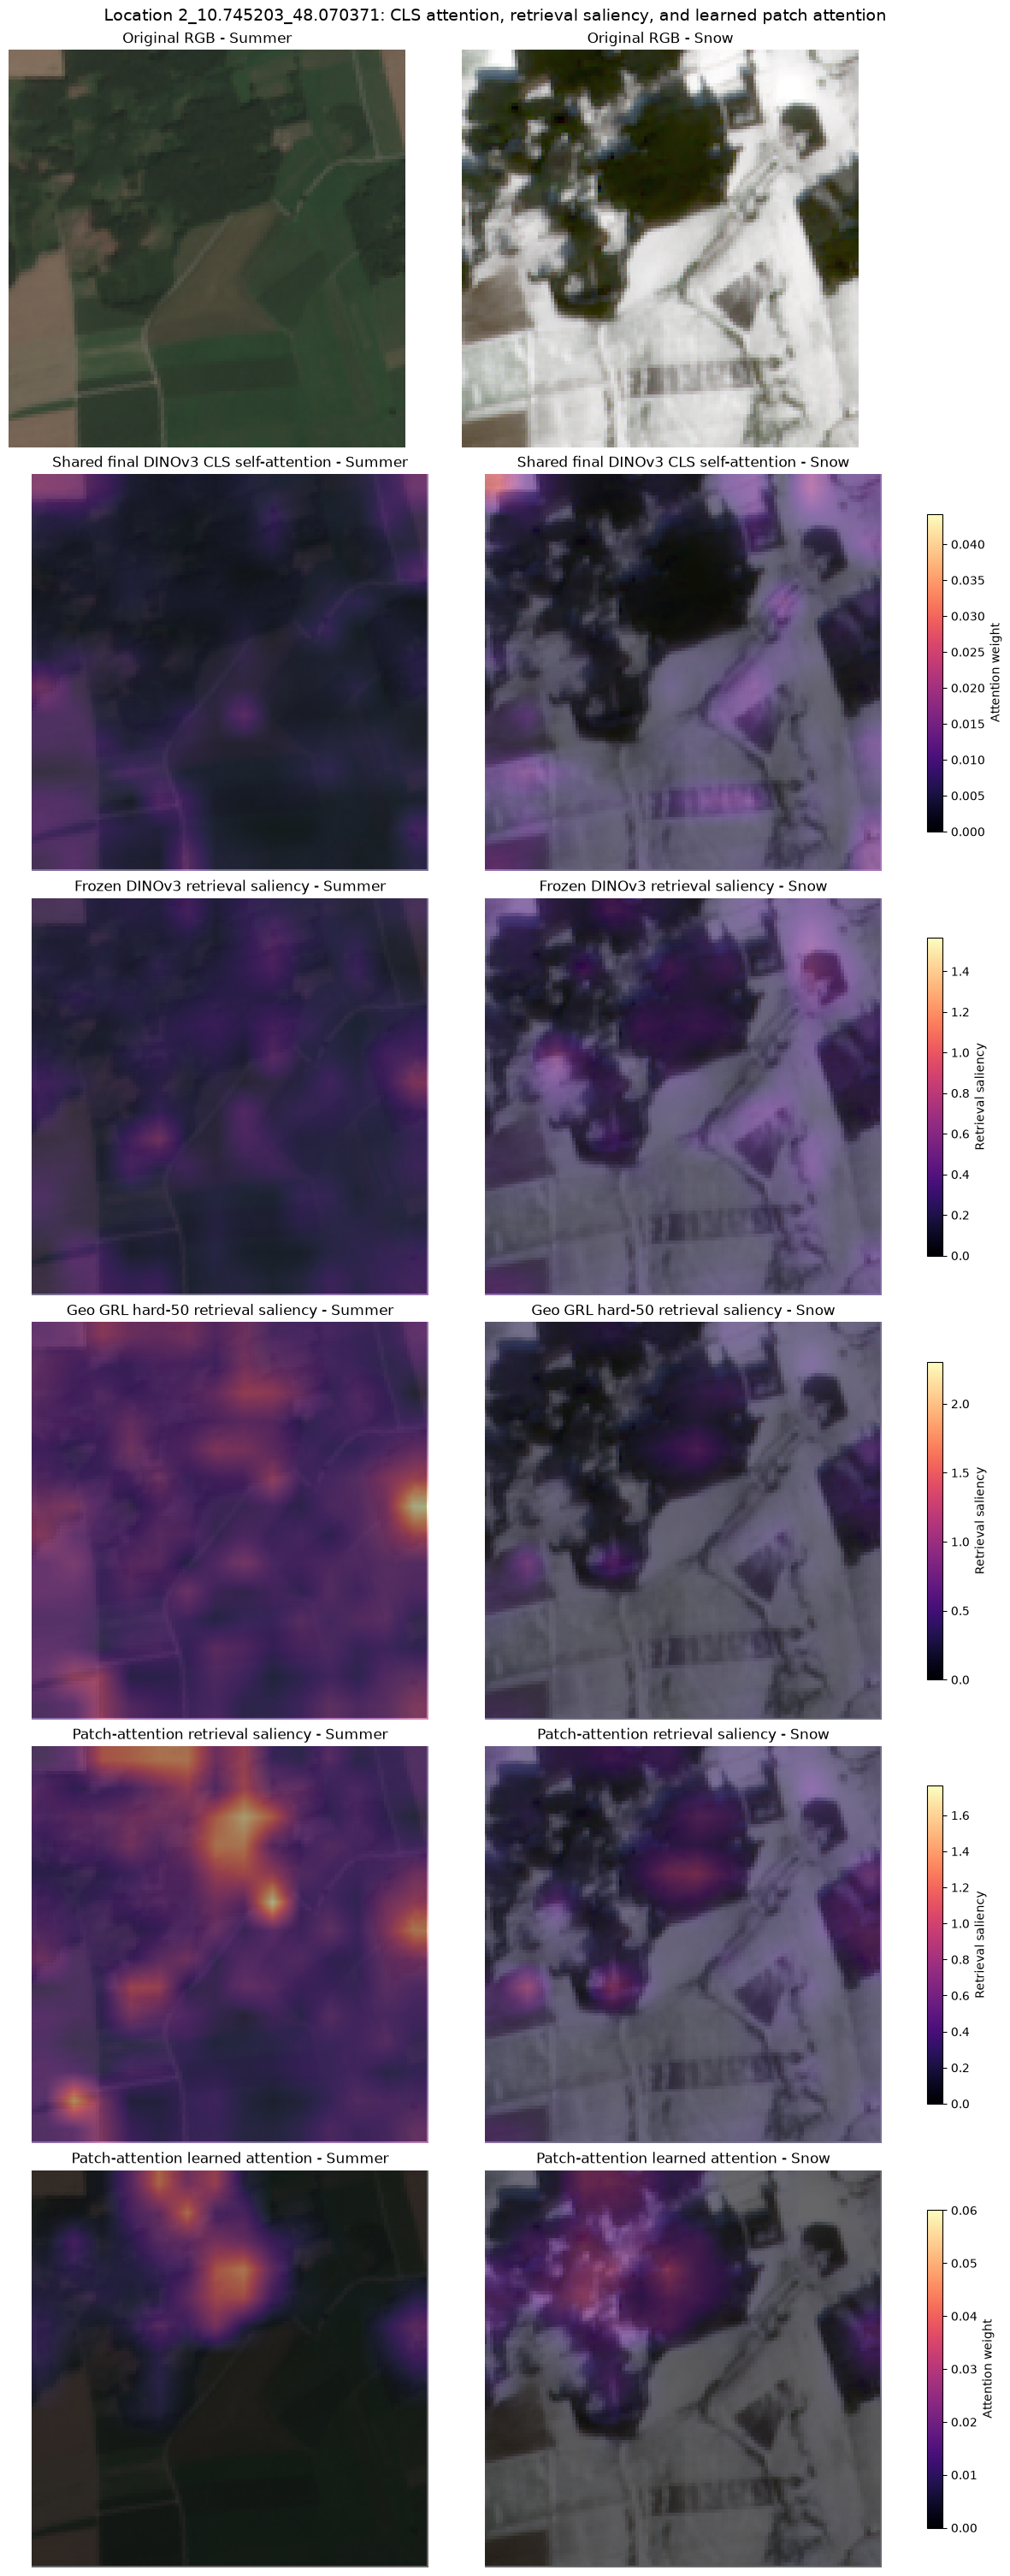

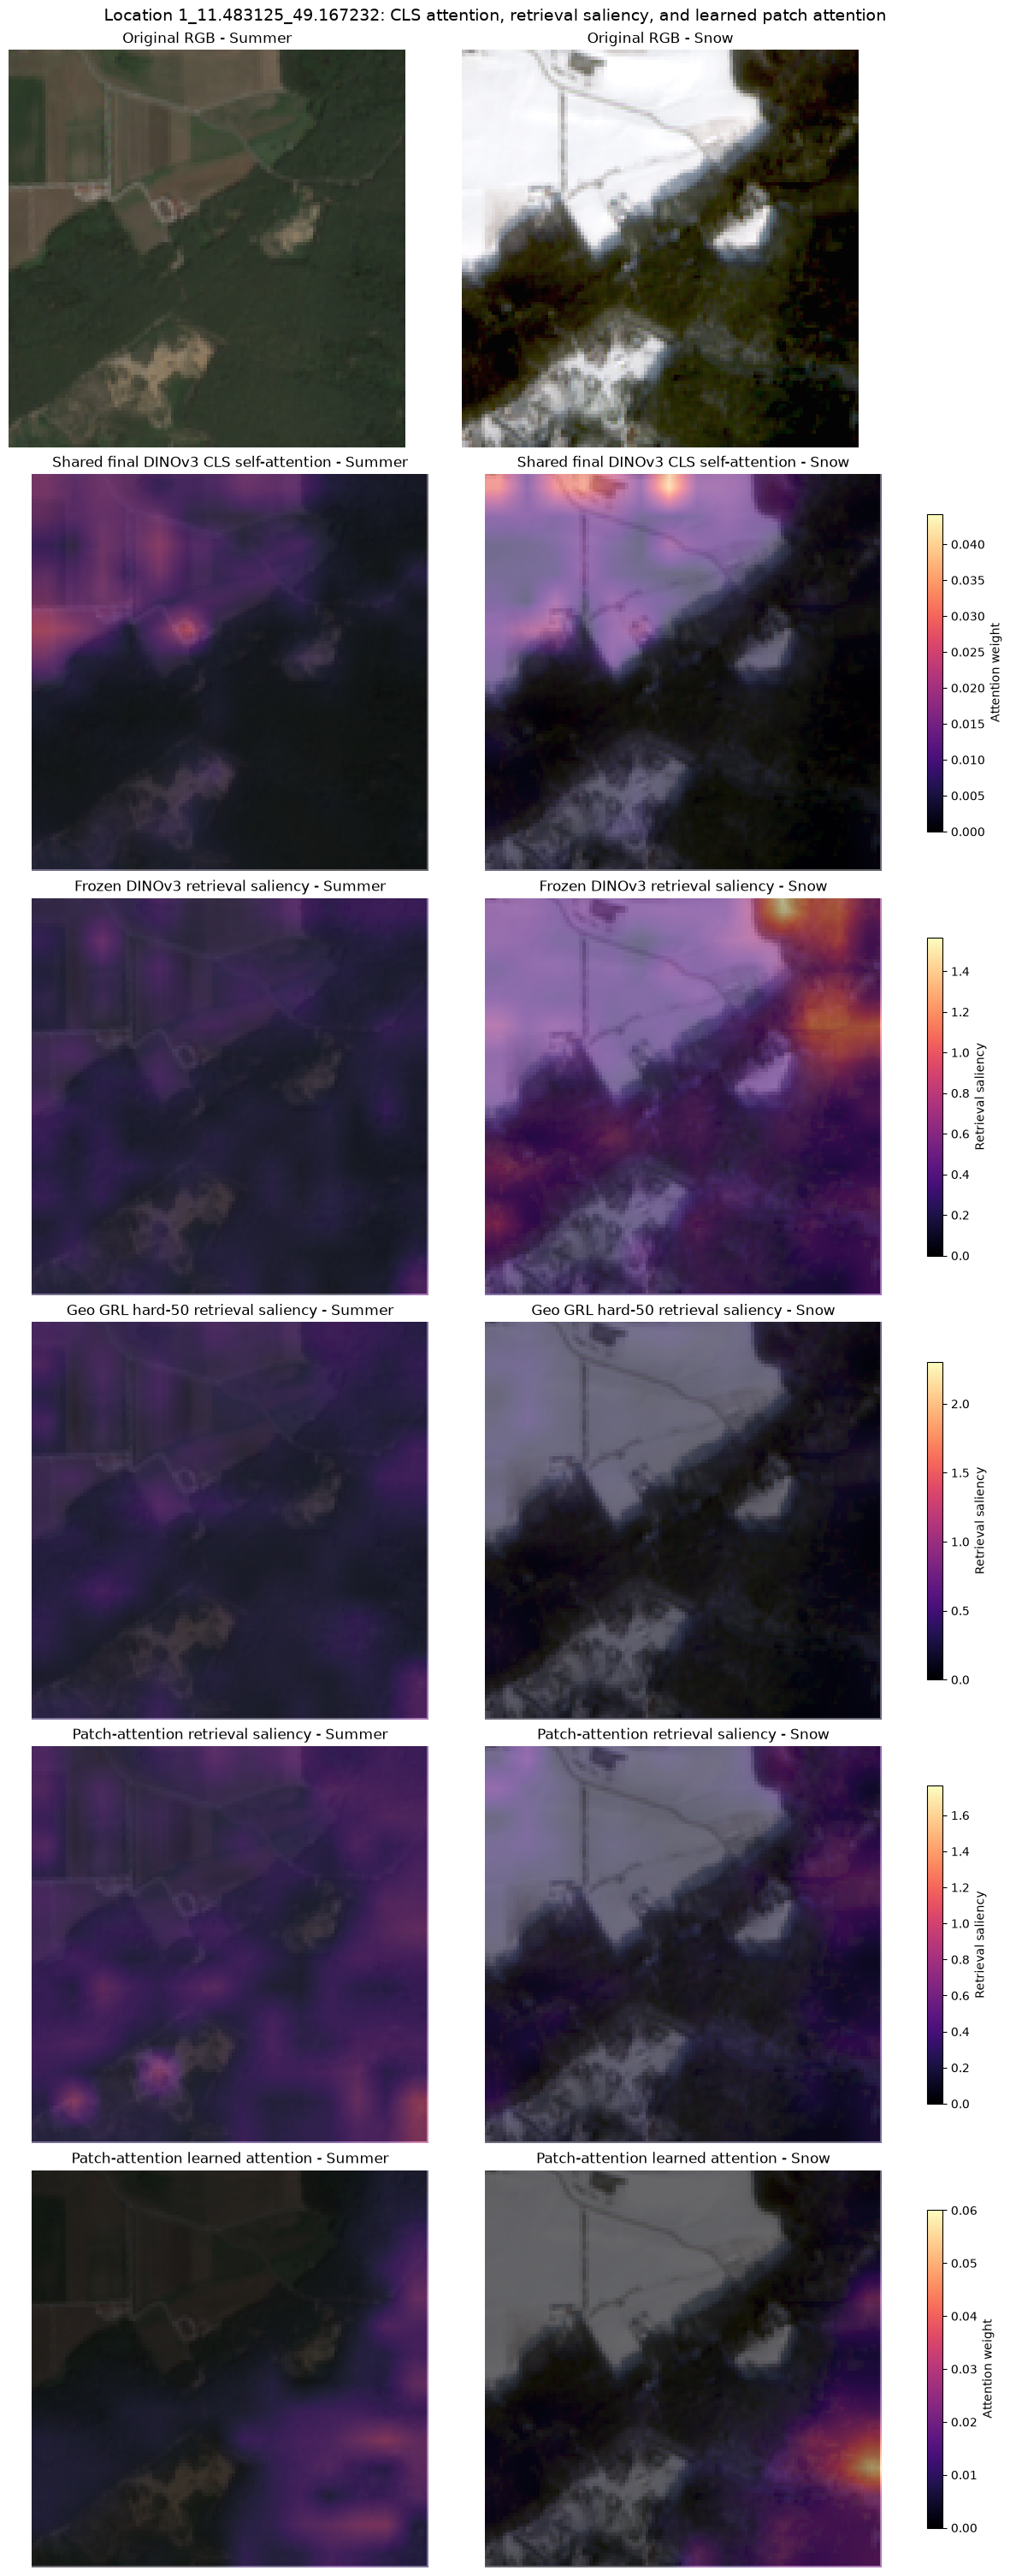

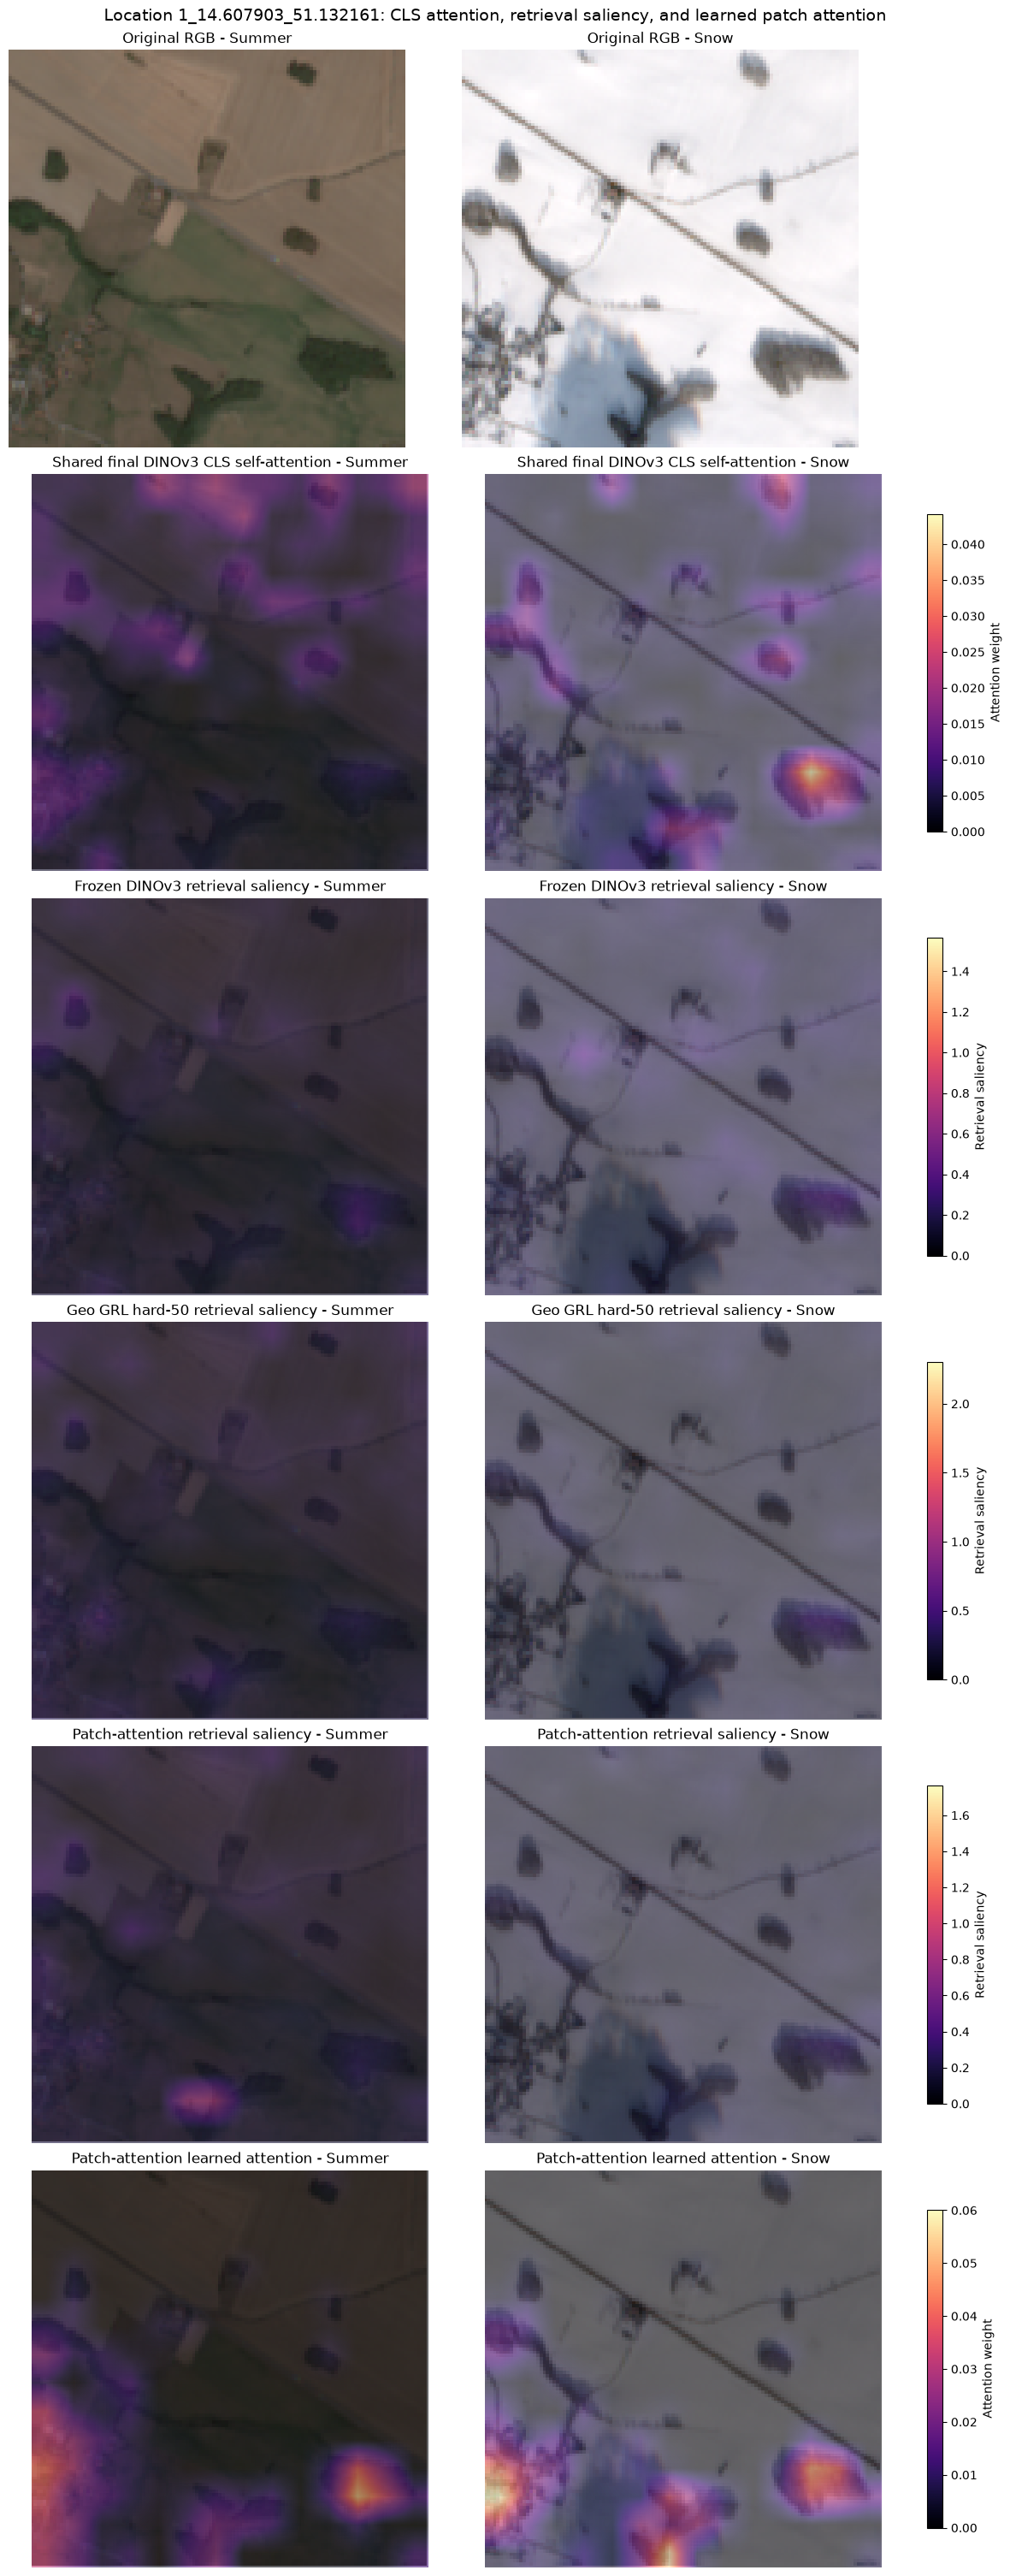

In [41]:
samples = []
for _, pair in selected_pairs.iterrows():
    summer_image, snow_image = dataset.load_pair(pair)
    images = preprocess_images(
        torch.stack((summer_image, snow_image)).to(device),
        model_cfg.image_size,
        tuple(model_cfg.normalization.mean),
        tuple(model_cfg.normalization.std),
    )
    with torch.inference_mode():
        _, learned_attention = patch_model.forward_embeddings(images, return_attention=True)
    if learned_attention is None:
        raise RuntimeError('The patch-attention model did not return attention weights.')

    patch_side = math.isqrt(learned_attention.shape[-1])
    if patch_side * patch_side != learned_attention.shape[-1]:
        raise ValueError(f'Expected a square patch grid, got {learned_attention.shape[-1]} patches')

    samples.append({
        'loc_id': pair[Pairs.LOC_ID],
        'images': [display_rgb(summer_image), display_rgb(snow_image)],
        'cls_attention': last_block_cls_attention(frozen_backbone, images).cpu(),
        'frozen_saliency': retrieval_similarity_saliency(
            frozen_backbone,
            lambda inputs: torch.nn.functional.normalize(frozen_backbone(inputs), dim=-1),
            images,
        ).cpu(),
        'geo_saliency': retrieval_similarity_saliency(
            geo_model.backbone, geo_model.forward_embeddings, images
        ).cpu(),
        'patch_saliency': retrieval_similarity_saliency(
            patch_model.backbone, patch_model.forward_embeddings, images
        ).cpu(),
        'learned': learned_attention.cpu().reshape(2, patch_side, patch_side),
    })

map_specs = [
    ('Shared final DINOv3 CLS self-attention', 'cls_attention'),
    ('Frozen DINOv3 retrieval saliency', 'frozen_saliency'),
    ('Geo GRL hard-50 retrieval saliency', 'geo_saliency'),
    ('Patch-attention retrieval saliency', 'patch_saliency'),
    ('Patch-attention learned attention', 'learned'),
]
normalizers = {
    key: Normalize(vmin=0, vmax=max(sample[key].max().item() for sample in samples))
    for _, key in map_specs
}

for sample in samples:
    fig, axes = plt.subplots(1 + len(map_specs), 2, figsize=(12, 5 * (1 + len(map_specs))), constrained_layout=True)
    for column, (season, image) in enumerate(zip(['Summer', 'Snow'], sample['images'])):
        axes[0, column].imshow(image)
        axes[0, column].set_title(f'Original RGB - {season}')
        axes[0, column].axis('off')

        image_height, image_width = image.shape[:2]
        for row_index, (map_label, key) in enumerate(map_specs, start=1):
            axes[row_index, column].imshow(image)
            axes[row_index, column].imshow(
                sample[key][column].numpy(),
                cmap=COLORMAP,
                norm=normalizers[key],
                alpha=0.60,
                interpolation='bilinear',
                extent=(0, image_width, image_height, 0),
            )
            axes[row_index, column].set_title(f'{map_label} - {season}')
            axes[row_index, column].axis('off')

    for row_index, (map_label, key) in enumerate(map_specs, start=1):
        fig.colorbar(
            ScalarMappable(norm=normalizers[key], cmap=COLORMAP),
            ax=axes[row_index],
            label=('Attention weight' if key in ('cls_attention', 'learned') else 'Retrieval saliency'),
            shrink=0.80,
        )
    fig.suptitle(
        f'Location {sample["loc_id"]}: CLS attention, retrieval saliency, and learned patch attention',
        fontsize=14,
    )
    plt.show()

## LoRA vs frozen DINOv3

The models above keep the backbone frozen, so their CLS self-attention is the frozen DINOv3 map. LoRA adapts blocks 10-11, so its last-block CLS self-attention can change. The checkpoint comes from `scripts/train_cached_lora.py` with no patch attention: plain CLS token plus residual head.

This section only needs the LoRA checkpoint and the setup and helper-function cells at the top (not the other checkpoints). It uses the validation split because the LoRA checkpoint was selected on val and test stays held out. On val, LoRA reaches 99.4% mean Recall@1 against 73.1% for a frozen run with the same settings.


In [ ]:
LORA_CHECKPOINT_PATH = REPO_DIR / (
    'artifacts/checkpoints/dinov3_vits16_cached_lora_residual_b128_hn1_w0.0_15ep_best.pt'
)
LORA_SPLIT = 'val'
LORA_LOC_IDS = ['1_11.524806_49.339061']
LORA_SAMPLE_COUNT = 2  # Random extra pairs from LORA_SPLIT, added to LORA_LOC_IDS.
CORRELATION_LOCATIONS = 1000  # Pairs used for the summer/snow attention correlation.
CORRELATION_BATCH_SIZE = 64
LORA_RANDOM_SEED = 42
LORA_COLORMAP = 'magma'

lora_available = LORA_CHECKPOINT_PATH.is_file()
if lora_available:
    lora_device = get_device()
    lora_model, lora_cfg = load_trained_model(LORA_CHECKPOINT_PATH, lora_device)
    lora_frozen_backbone = load_frozen_backbone(
        lora_cfg.backbone, lora_cfg.repository, lora_cfg.weights
    ).to(lora_device)

    lora_preprocessing_cfg = OmegaConf.load(REPO_DIR / 'config/preprocessing_config.yaml')
    lora_artifacts_dir = REPO_DIR / lora_preprocessing_cfg.output.artifacts_dir
    lora_manifest = OmegaConf.load(lora_artifacts_dir / lora_preprocessing_cfg.output.manifest_filename)
    lora_pairs = pd.read_parquet(REPO_DIR / lora_manifest.pairs_path)
    lora_split_pairs = lora_pairs.loc[lora_pairs[Pairs.SPLIT] == LORA_SPLIT].copy()
    lora_split_pairs[Pairs.LOC_ID] = lora_split_pairs[Pairs.LOC_ID].astype(str)
    lora_dataset = SeasoNetDataset(lora_pairs, split=LORA_SPLIT, data_dir=REPO_DIR / 'data')

    named_pairs = lora_split_pairs.loc[lora_split_pairs[Pairs.LOC_ID].isin(LORA_LOC_IDS)]
    missing_ids = set(LORA_LOC_IDS) - set(named_pairs[Pairs.LOC_ID])
    if missing_ids:
        raise ValueError(f'Location IDs are not in the {LORA_SPLIT!r} split: {sorted(missing_ids)}')
    extra_pairs = lora_split_pairs.drop(named_pairs.index).sample(n=LORA_SAMPLE_COUNT, random_state=LORA_RANDOM_SEED)
    lora_selected_pairs = pd.concat((named_pairs, extra_pairs))
    print(f'Visualizing {len(lora_selected_pairs)} {LORA_SPLIT} pairs: {lora_selected_pairs[Pairs.LOC_ID].tolist()}')
else:
    print(f'Skipping the LoRA section: no checkpoint at {LORA_CHECKPOINT_PATH}. Train one with scripts/train_cached_lora.py.')


Using: mps


Using LoRA adapters in 4 backbone linear layers
Using: dinov3_vits16 backbone


Visualizing 3 val pairs: ['1_11.524806_49.339061', '2_8.394734_51.039529', '1_12.827532_50.950747']


In [ ]:
def preprocess_pair(dataset, pair, device, cfg) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    summer_image, snow_image = dataset.load_pair(pair)
    images = preprocess_images(
        torch.stack((summer_image, snow_image)).to(device),
        cfg.image_size,
        tuple(cfg.normalization.mean),
        tuple(cfg.normalization.std),
    )
    return summer_image, snow_image, images


def map_correlation(first: torch.Tensor, second: torch.Tensor) -> torch.Tensor:
    """Pearson r between matching maps, batched over the first dimension."""
    first = first.flatten(1) - first.flatten(1).mean(dim=1, keepdim=True)
    second = second.flatten(1) - second.flatten(1).mean(dim=1, keepdim=True)
    return (first * second).sum(dim=1) / (first.norm(dim=1) * second.norm(dim=1))


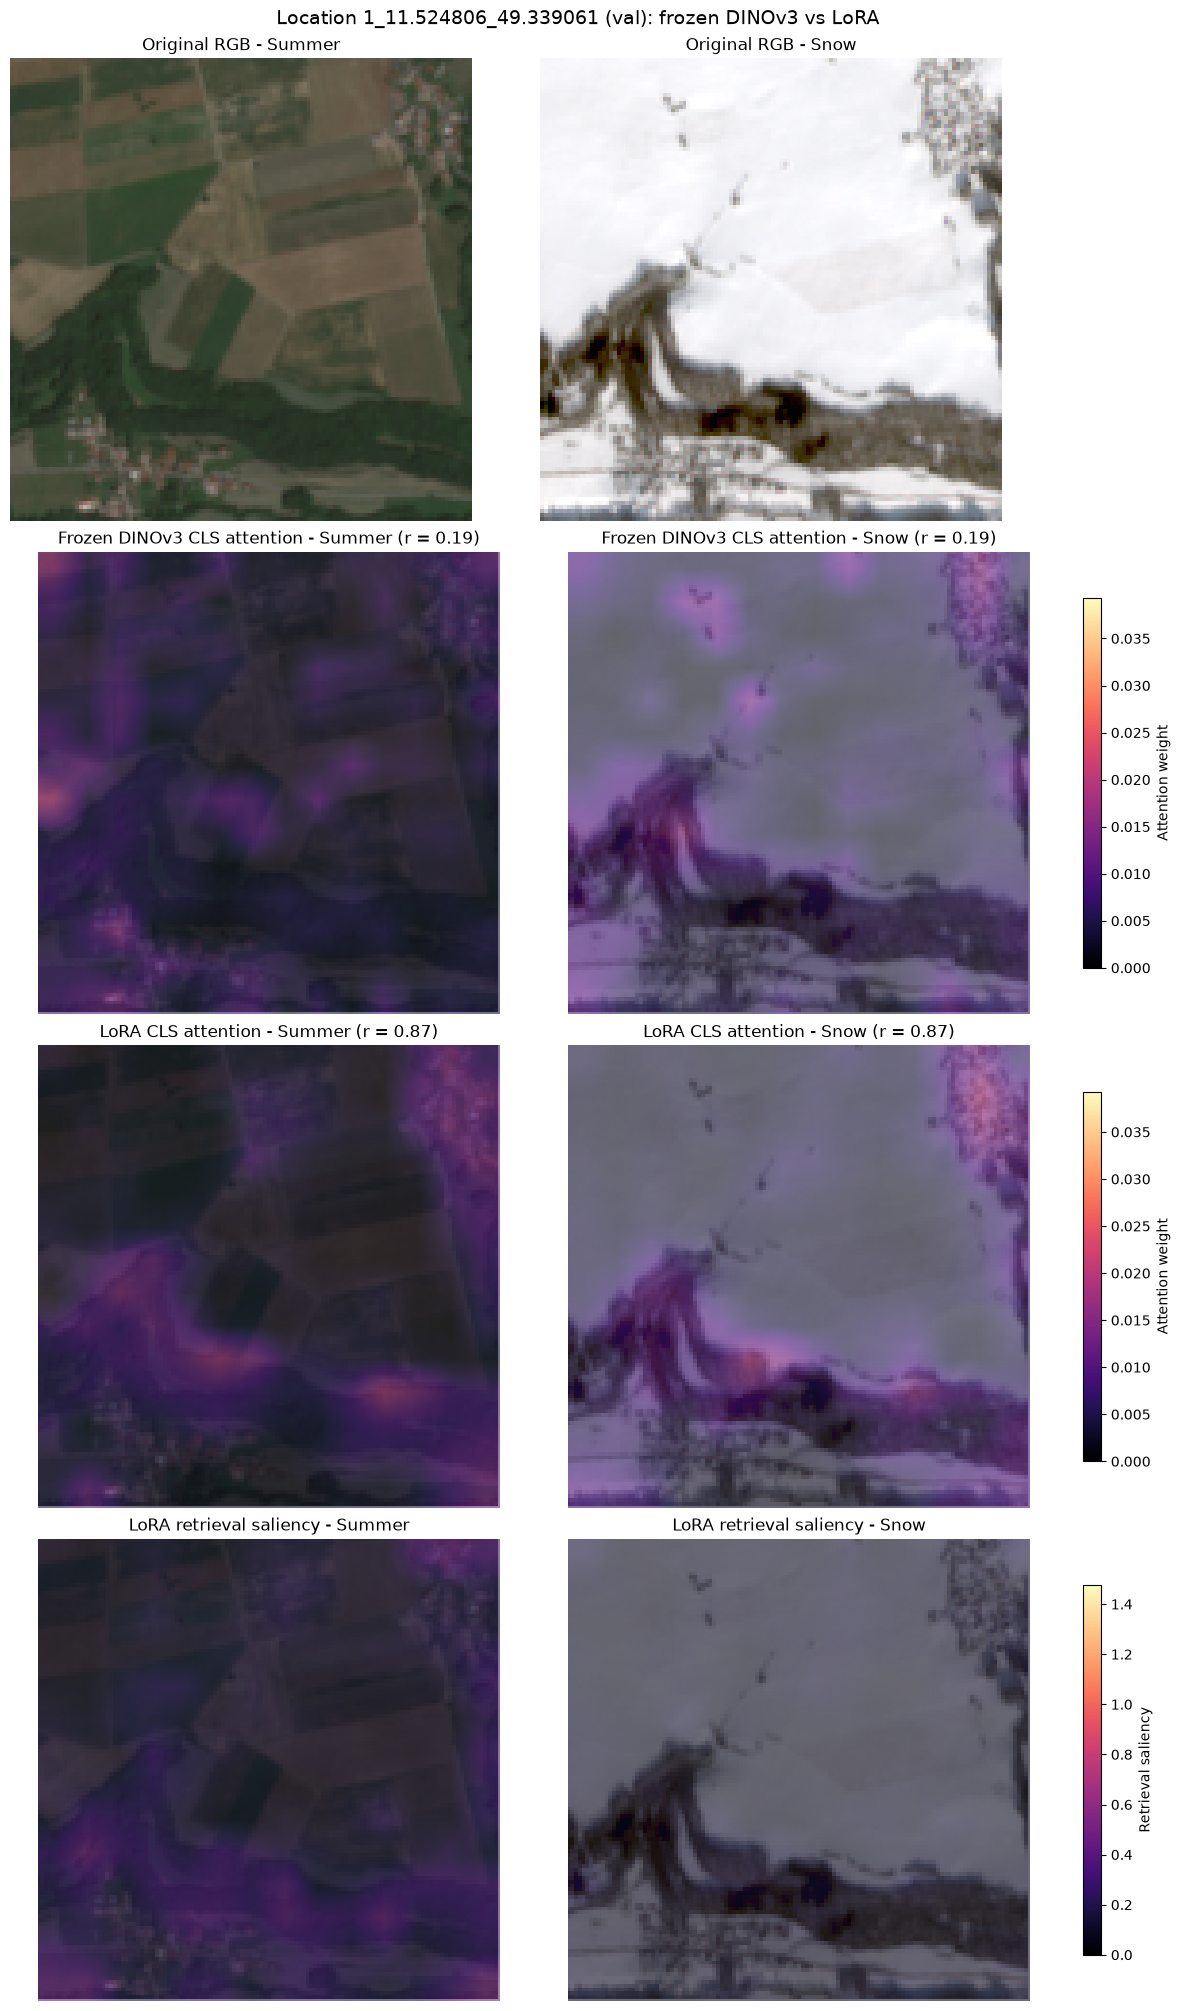

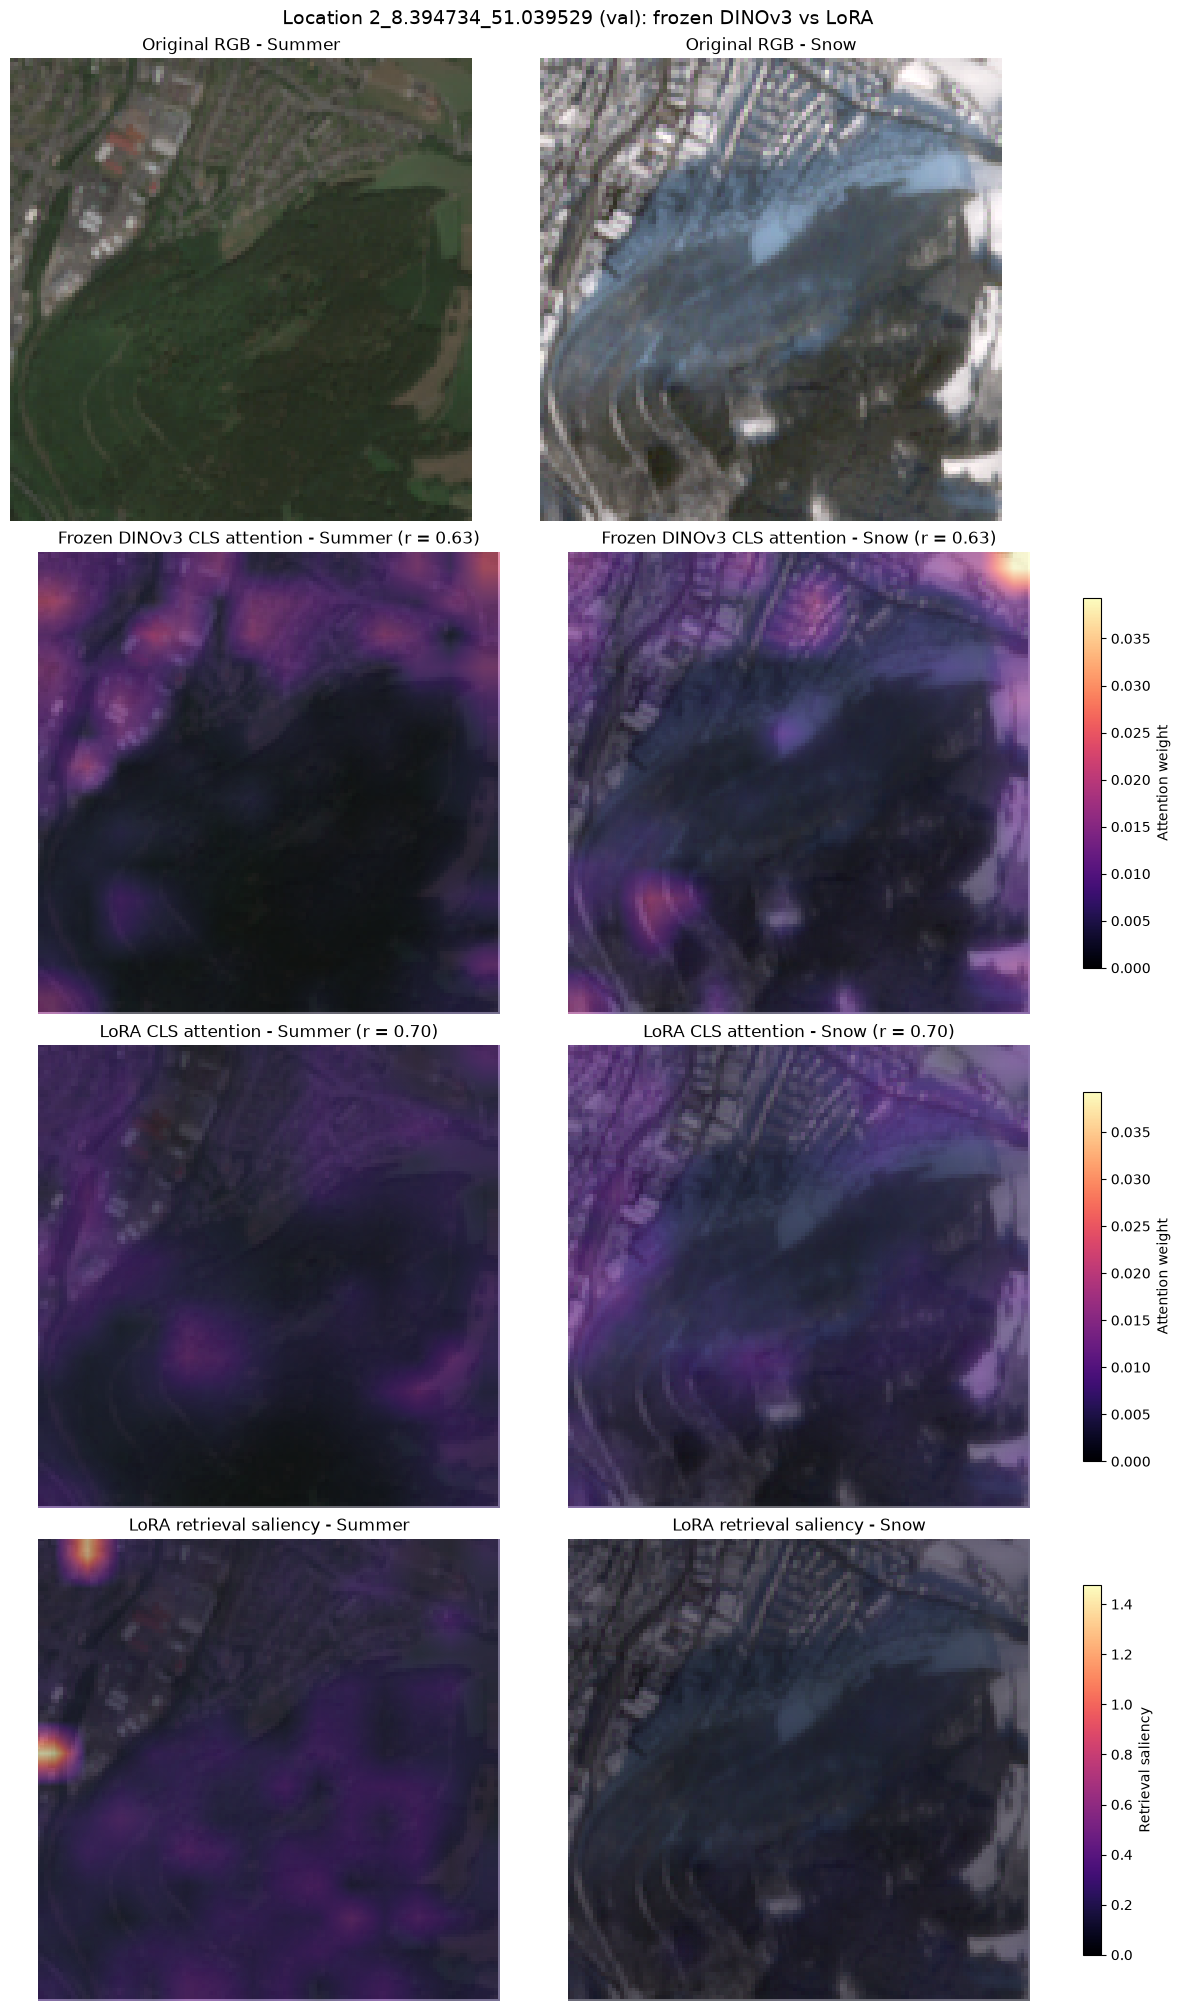

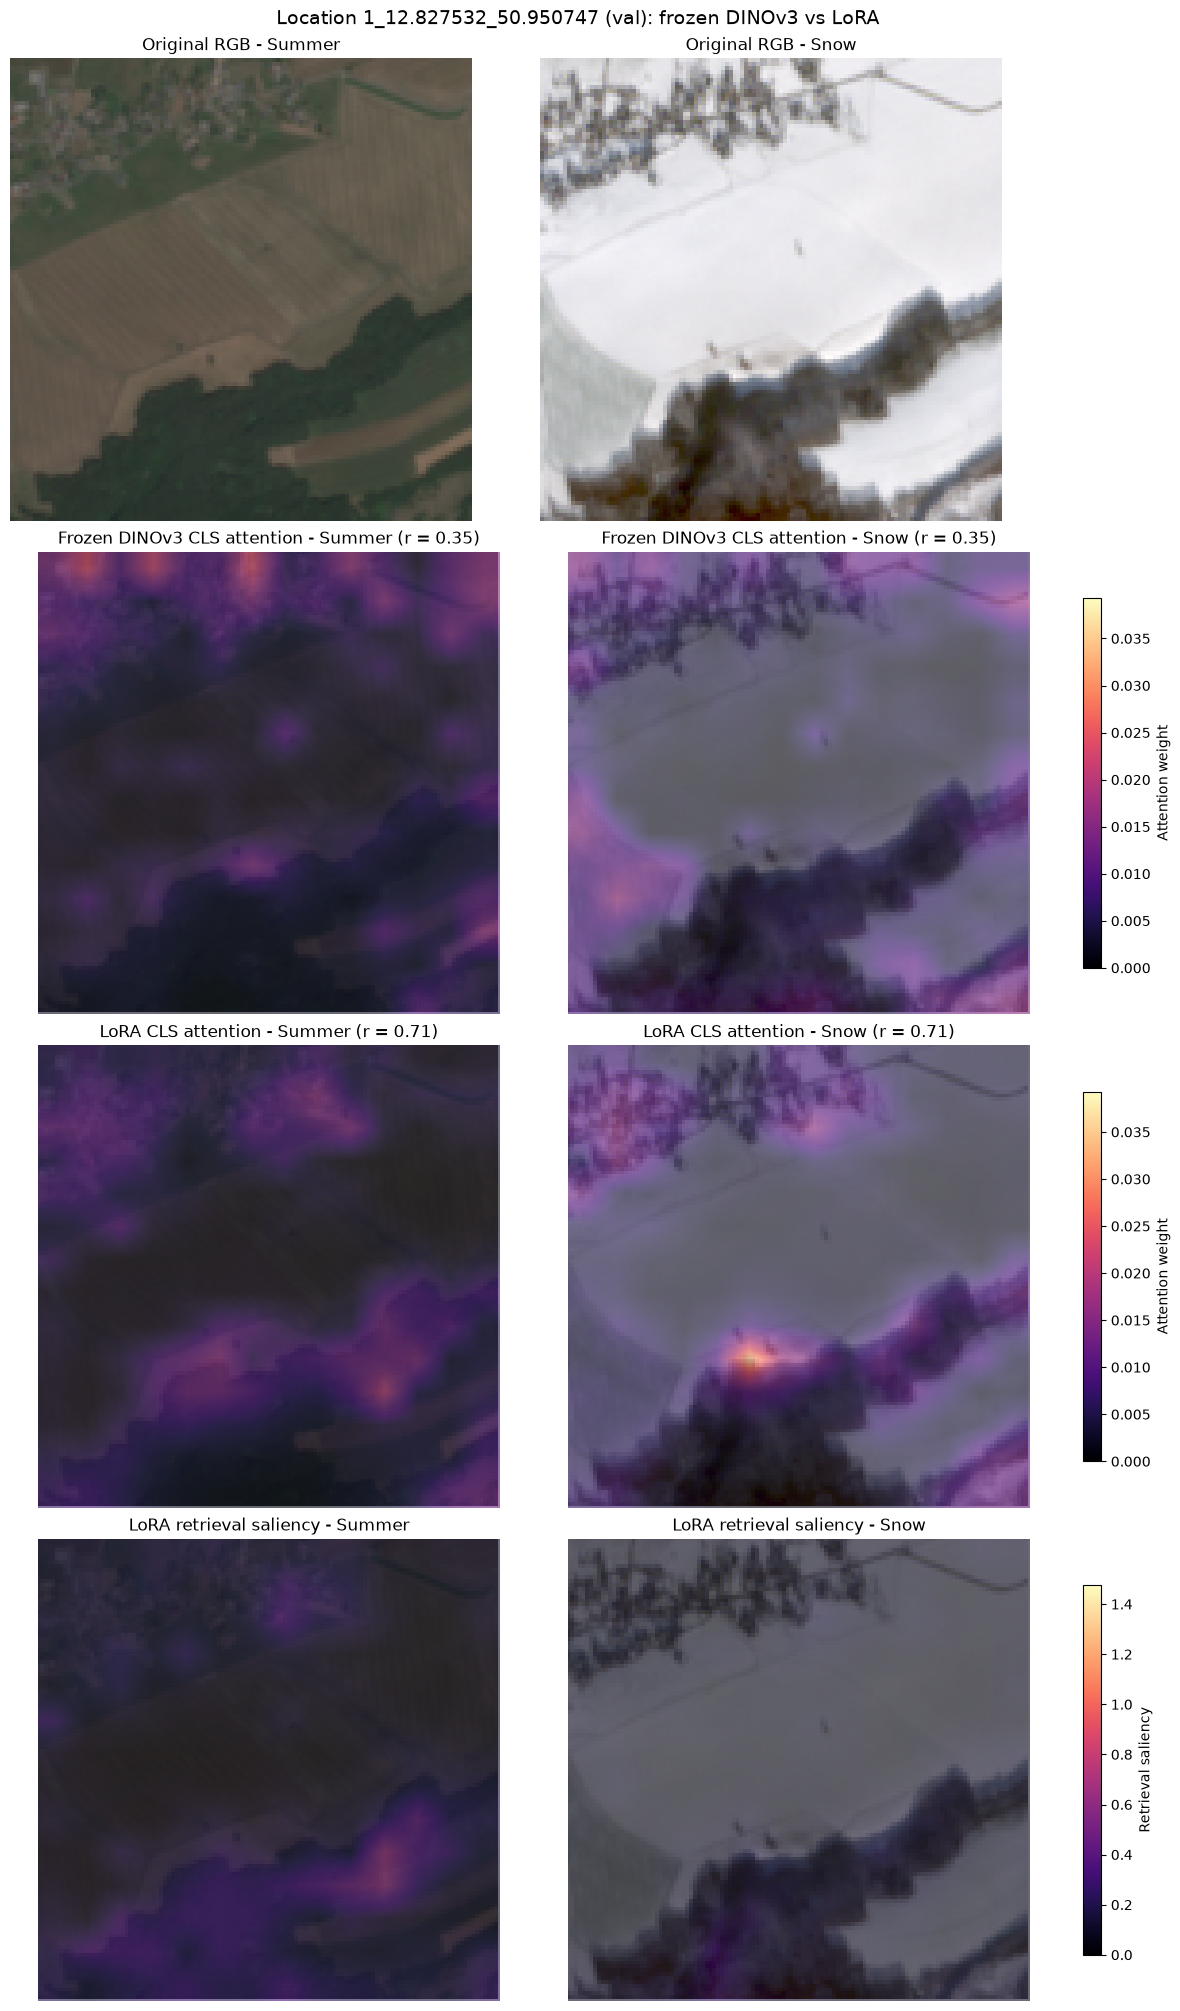

In [ ]:
if lora_available:
    lora_samples = []
    for _, pair in lora_selected_pairs.iterrows():
        summer_image, snow_image, images = preprocess_pair(lora_dataset, pair, lora_device, lora_cfg)
        frozen_attention = last_block_cls_attention(lora_frozen_backbone, images).cpu()
        lora_attention = last_block_cls_attention(lora_model.backbone, images).cpu()
        lora_samples.append({
            'loc_id': pair[Pairs.LOC_ID],
            'images': [display_rgb(summer_image), display_rgb(snow_image)],
            'frozen_cls_attention': frozen_attention,
            'lora_cls_attention': lora_attention,
            'lora_saliency': retrieval_similarity_saliency(
                lora_model.backbone, lora_model.forward_embeddings, images
            ).cpu(),
            'r': {
                'frozen_cls_attention': map_correlation(frozen_attention[:1], frozen_attention[1:]).item(),
                'lora_cls_attention': map_correlation(lora_attention[:1], lora_attention[1:]).item(),
            },
        })

    lora_map_specs = [
        ('Frozen DINOv3 CLS attention', 'frozen_cls_attention'),
        ('LoRA CLS attention', 'lora_cls_attention'),
        ('LoRA retrieval saliency', 'lora_saliency'),
    ]
    # Both CLS-attention rows share one scale so they can be compared directly.
    cls_attention_max = max(
        sample[key].max().item()
        for sample in lora_samples
        for key in ('frozen_cls_attention', 'lora_cls_attention')
    )
    lora_normalizers = {
        'frozen_cls_attention': Normalize(vmin=0, vmax=cls_attention_max),
        'lora_cls_attention': Normalize(vmin=0, vmax=cls_attention_max),
        'lora_saliency': Normalize(vmin=0, vmax=max(sample['lora_saliency'].max().item() for sample in lora_samples)),
    }

    for sample in lora_samples:
        fig, axes = plt.subplots(
            1 + len(lora_map_specs), 2, figsize=(12, 5 * (1 + len(lora_map_specs))), constrained_layout=True
        )
        for column, (season, image) in enumerate(zip(['Summer', 'Snow'], sample['images'])):
            axes[0, column].imshow(image)
            axes[0, column].set_title(f'Original RGB - {season}')
            axes[0, column].axis('off')

            image_height, image_width = image.shape[:2]
            for row_index, (map_label, key) in enumerate(lora_map_specs, start=1):
                axes[row_index, column].imshow(image)
                axes[row_index, column].imshow(
                    sample[key][column].numpy(),
                    cmap=LORA_COLORMAP,
                    norm=lora_normalizers[key],
                    alpha=0.60,
                    interpolation='bilinear',
                    extent=(0, image_width, image_height, 0),
                )
                title = f'{map_label} - {season}'
                if key in sample['r']:
                    title += f' (r = {sample["r"][key]:.2f})'
                axes[row_index, column].set_title(title)
                axes[row_index, column].axis('off')

        for row_index, (map_label, key) in enumerate(lora_map_specs, start=1):
            fig.colorbar(
                ScalarMappable(norm=lora_normalizers[key], cmap=LORA_COLORMAP),
                ax=axes[row_index],
                label='Attention weight' if 'attention' in key else 'Retrieval saliency',
                shrink=0.80,
            )
        fig.suptitle(f'Location {sample["loc_id"]} ({LORA_SPLIT}): frozen DINOv3 vs LoRA', fontsize=14)
        plt.show()


### Do the summer and snow attention maps agree?

For each pair, Pearson r between the summer and snow last-block CLS attention maps. If the model looks at the same ground in both seasons, r is high.


Frozen DINOv3: mean r = 0.42, median r = 0.42 over 1000 val pairs
LoRA: mean r = 0.77, median r = 0.78 over 1000 val pairs


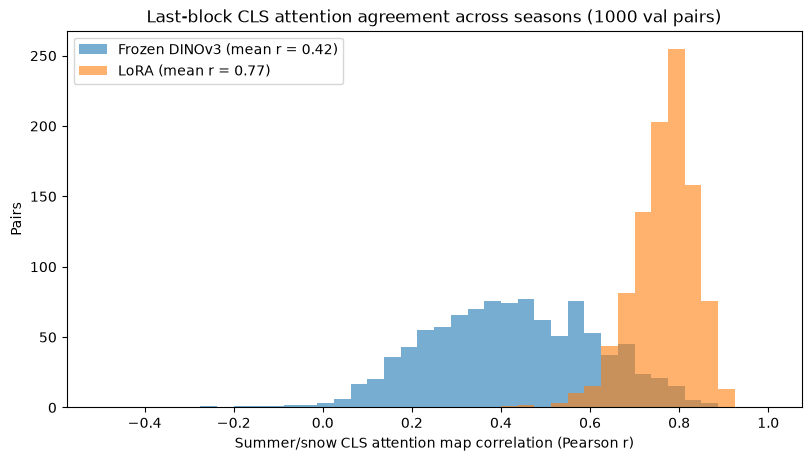

In [ ]:
if lora_available:
    correlation_pairs = lora_split_pairs.sample(
        n=min(CORRELATION_LOCATIONS, len(lora_split_pairs)), random_state=LORA_RANDOM_SEED
    )
    correlations = {'Frozen DINOv3': [], 'LoRA': []}
    for start in range(0, len(correlation_pairs), CORRELATION_BATCH_SIZE):
        batch = correlation_pairs.iloc[start:start + CORRELATION_BATCH_SIZE]
        summer_images, snow_images = zip(*(lora_dataset.load_pair(pair) for _, pair in batch.iterrows()))
        images = preprocess_images(
            torch.stack(summer_images + snow_images).to(lora_device),
            lora_cfg.image_size,
            tuple(lora_cfg.normalization.mean),
            tuple(lora_cfg.normalization.std),
        )
        for label, backbone in (('Frozen DINOv3', lora_frozen_backbone), ('LoRA', lora_model.backbone)):
            attention = last_block_cls_attention(backbone, images).cpu()
            correlations[label].append(map_correlation(attention[:len(batch)], attention[len(batch):]))
    correlations = {label: torch.cat(values) for label, values in correlations.items()}

    fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
    for label, values in correlations.items():
        ax.hist(values.numpy(), bins=40, range=(-0.5, 1), alpha=0.6, label=f'{label} (mean r = {values.mean():.2f})')
        print(f'{label}: mean r = {values.mean():.2f}, median r = {values.median():.2f} over {len(values)} {LORA_SPLIT} pairs')
    ax.set_xlabel('Summer/snow CLS attention map correlation (Pearson r)')
    ax.set_ylabel('Pairs')
    ax.set_title(f'Last-block CLS attention agreement across seasons ({len(correlation_pairs)} {LORA_SPLIT} pairs)')
    ax.legend()
    plt.show()
